# Concentration paper


In [1]:
import math
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import functools

def set_seed(s):
    import random
    random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
    np.random.seed(s)
    # torch.backends.cudnn.deterministic = True
    # torch.backends.cudnn.benchmark = False

set_seed(0)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class ScaledSigmoid(nn.Module):
    def __init__(self, min_val, max_val):
        super(ScaledSigmoid, self).__init__()
        self.min_val = min_val
        self.max_val = max_val

    def forward(self, x):
        # Apply sigmoid to squish the output to (0, 1)
        x = torch.sigmoid(x)
        # Scale and shift to the desired range [min_val, max_val]
        return self.min_val + x * (self.max_val - self.min_val)

class EquationValue(nn.Module):
    def __init__(self, input_dims, min_val, max_val):
        super().__init__()
        assert min_val < max_val, "min_val must be less than max_val"
        self.min_val = min_val
        self.max_val = max_val
        self.scaled_sigmoid = ScaledSigmoid(min_val, max_val)
        self.input_dims = input_dims
        self.linear = nn.Linear(input_dims, 1)     

        # # Target a pre-activation range of approximately [-4, 4].
        # # If we assume inputs are roughly unit variance, then scale the weights:
        # weight_range = self.max_val / math.sqrt(input_dims)  # This is a heuristic value.
        # nn.init.uniform_(self.linear.weight, -weight_range, weight_range)
        
        # # Similarly, initialize biases to cover a wide range.
        # # Here we set biases uniformly over [-4,4].
        # nn.init.uniform_(self.linear.bias, self.min_val, self.max_val)  

    def forward(self, x):
        # Apply the linear layer
        x = self.linear(x)
        # Apply the scaled sigmoid activation function
        x = self.scaled_sigmoid(x)
        return x

class DiscoveryNet(nn.Module):
    def __init__(self, input_dim, output_dim, n_units=100, epochs=1000, loss = nn.MSELoss(), lr=1e-3, loss2=None, loss2_weight=0.1, patience=0) -> None:
        super().__init__()

        self.input_dim = input_dim
        self.output_dim = output_dim
        self.epochs = epochs
        self.loss = loss
        self.loss2 = loss2
        self.loss2_weight = loss2_weight
        self.lr = lr 
        self.n_units = n_units
        self.patience = patience
    
        self.layers = nn.Sequential(
            nn.Linear(input_dim, self.n_units),
            nn.ReLU(),
            nn.Linear(self.n_units,self.n_units),
            nn.ReLU(),
            nn.Linear(self.n_units,self.n_units),
            nn.ReLU(),
            nn.Linear(self.n_units,self.n_units),
            nn.ReLU(),
        )
        # self.out = nn.Linear(self.n_units, output_dim)

        self.d = EquationValue(self.n_units, 0, 1)
        # self.Ea = EquationValue(self.n_units, 30000, 70000)
        # self.A = EquationValue(self.n_units, 1e-5, 1e-1)  # 0.00001 to 0.1
        # self.n = EquationValue(self.n_units, 1, 3) 
        self.log_Ea = nn.Parameter(torch.log(torch.tensor(35000, dtype=torch.float32, device=DEVICE, requires_grad=True)))
        self.log_B = nn.Parameter(torch.log(torch.tensor(1e-3,dtype=torch.float32, device=DEVICE, requires_grad=True)))
        self.log_n = nn.Parameter(torch.log(torch.tensor(2.0, dtype=torch.float32, device=DEVICE,requires_grad=True)))
        self.log_rmax = nn.Parameter(torch.log(torch.tensor(8e-9, dtype=torch.float32, device=DEVICE,requires_grad=True)))
        self.log_m = nn.Parameter(torch.log(torch.tensor(1e-2, dtype=torch.float32, device=DEVICE,requires_grad=True)))

    @property
    def Ea(self):
        return torch.exp(self.log_Ea)
    
    @Ea.setter
    def Ea(self, value):
        value = torch.tensor(value, dtype=torch.float32, device=DEVICE, requires_grad=True)
        self.log_Ea = nn.Parameter(torch.log(value))

    @property
    def B(self):
        return torch.exp(self.log_B)
    
    @B.setter
    def B(self, value):
        value = torch.tensor(value, dtype=torch.float32, device=DEVICE, requires_grad=True)
        self.log_B = nn.Parameter(torch.log(value))

    @property
    def n(self):
        return torch.exp(self.log_n)

    @n.setter
    def n(self, value):
        value = torch.tensor(value, dtype=torch.float32, device=DEVICE, requires_grad=True)
        self.log_n = nn.Parameter(torch.log(value))

    @property
    def m(self):
        return torch.exp(self.log_m)

    @m.setter
    def m(self, value):
        value = torch.tensor(value, dtype=torch.float32, device=DEVICE, requires_grad=True)
        self.log_m = nn.Parameter(torch.log(value))

    def forward(self, x):
        h = self.layers(x)

        d = self.d(h)

        return d
    
    def fit(self, X, y, scaler=None):
        Xt = np_to_tensor(X)
        yt = np_to_tensor(y)

        optimiser = optim.Adam(self.parameters(), lr=self.lr)
        self.train()
        losses = []
        data_losses = []
        physic_losses = []
        for ep in range(self.epochs):
            optimiser.zero_grad()
            outputs = self.forward(Xt)

            # d = outputs[:, 0].reshape(-1, 1)
            # d = scaler.inverse_transform(d).type(torch.float32) if scaler else d

            if self.loss2:
                data_loss = self.loss(yt, outputs)
                # data_loss = torch.pow(data_loss, 1/0.04)
                physic_loss = self.loss2_weight * self.loss2(self)
                loss = data_loss + physic_loss
                physic_losses.append(physic_loss.item())
                data_losses.append(data_loss.item())
            else:
                loss = self.loss(yt, outputs)
                data_losses.append(loss.item())

            loss.backward()
            optimiser.step()
            losses.append(loss.item())

            if torch.isnan(loss).any():
                print("Loss is NaN, stopping training.")
                raise ValueError("Loss is NaN")

            if ep % int(self.epochs / 10) == 0:
                if physic_losses:
                    physic_loss_avg = np.mean(physic_losses).item()
                    # print("Estimated Ea :", outputs[:, 1].reshape(-1, 1).mean().item())
                    # print("Estimated A :", outputs[:, 2].reshape(-1, 1).mean().item())
                    estimateds = f"Ea={self.Ea.item():.2f}, B={self.B.item():.2e}, n={self.n.item():.2f}, m={self.m.item():.2e}"
                else:
                    physic_loss_avg = 0
                    estimateds = ""

                print(f"Epoch {ep}/{self.epochs}, loss: {np.mean(losses).item():.6f} - data_loss: {np.mean(data_losses).item():.6f} - physic_loss: {physic_loss_avg:.6f} - {estimateds}")
        return losses

    def predict(self, X):
        self.eval()
        out = self.forward(np_to_tensor(X))
        return out.detach().cpu().numpy()

def np_to_tensor(x):
    if isinstance(x, torch.Tensor) and x.device == DEVICE:
        return x
    elif isinstance(x, torch.Tensor):
        return x.to(DEVICE)
    elif isinstance(x, list):
        x = np.array(x)
    
    n_samples = len(x)
    return torch.from_numpy(x).to(torch.float).to(DEVICE).reshape(n_samples, -1)

In [2]:
# testing equationValue

etest = [EquationValue(10, 0, 1), EquationValue(10, 1, 3), EquationValue(10, 20000, 100000), EquationValue(10, 1e-5, 1e-1)]
# x = torch.randn(10, 10) ** 10
# print(x.min(), x.max())
for e in etest:
    tests = torch.cat([e(torch.randn(10, 10)) for i in range(50)])
    print(tests.min(), tests.max())

tensor(0.1923, grad_fn=<MinBackward1>) tensor(0.8051, grad_fn=<MaxBackward1>)
tensor(1.3987, grad_fn=<MinBackward1>) tensor(2.7688, grad_fn=<MaxBackward1>)
tensor(27197.0117, grad_fn=<MinBackward1>) tensor(86786.6484, grad_fn=<MaxBackward1>)
tensor(0.0101, grad_fn=<MinBackward1>) tensor(0.0795, grad_fn=<MaxBackward1>)


In [3]:
class TorchMinMaxScaler(nn.Module):
    def __init__(self):
        super().__init__()
        self.min_val = torch.tensor(0, dtype=torch.float32, device=DEVICE)
        self.max_val = torch.tensor(1, dtype=torch.float32, device=DEVICE)

    def fit_transform(self, data):
        # Compute min and max values from the data
        if not isinstance(data, torch.Tensor):
            data = torch.from_numpy(data)
        self.min_val = torch.min(data, dim=0)[0].to(device=DEVICE)
        self.max_val = torch.max(data, dim=0)[0].to(device=DEVICE)
        return self.transform(data)
    
    def transform(self, x):
        prev = None
        if not isinstance(x, torch.Tensor):
            x = torch.from_numpy(x).to(device=DEVICE)
        if x.device != DEVICE:
            prev  = x.device
            x = x.to(device=DEVICE)
        # Scale x to the range [0, 1]
        scaled = (x - self.min_val) / (self.max_val - self.min_val)
        if prev != DEVICE:
            scaled = scaled.to(device=prev)
        return scaled.type(torch.float32)
    
    def inverse_transform(self, x_scaled):
        # Inverse scaling: bring x_scaled back to original range
        return x_scaled * (self.max_val - self.min_val) + self.min_val

Text(0.5, 0, 'Time (s)')

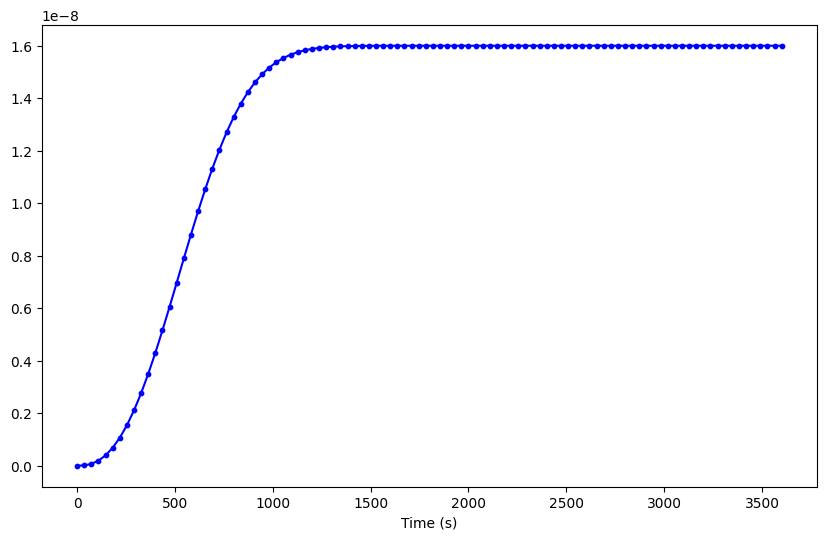

In [4]:
import numpy as np
import functools
import matplotlib.pyplot as plt

# def avrami_law(t,Ea,R,T,A,n,r_max):
#     K = A * np.exp(-Ea / (R * T))
#     d = r_max * (1 - np.exp(-K * t**n))

#     return d

def avrami_law(t,Ea,R,T,B,n,m, r_max=16e-9):
    K = B*np.pow(T, m) * np.exp(-Ea / (R * T))
    d = r_max*(1 - np.exp(-K * t**n))
    return d

np.random.seed(10)
guessed_B = 1e-3              # Increased to speed up transformation
guessed_Ea = 35000            # Lowered to increase reaction rate
T = 453               # Higher temp for faster growth
r_max = 1 #          # Max radius 
guessed_n = 2.5
R = 8.314
guessed_m = 1e-2

TIME_MAX = 3600  # seconds

# Time array
times = np.linspace(0, TIME_MAX, 100)
eq = functools.partial(avrami_law, Ea=guessed_Ea, B=guessed_B, m=guessed_m, T=T, n=guessed_n, R=R)
values = eq(times)

plt.figure(figsize=(10, 6))
plt.plot(times, values, label='Avrami Law', color='blue')
plt.scatter(times, values, color='blue', s=10)
plt.xlabel('Time (s)')

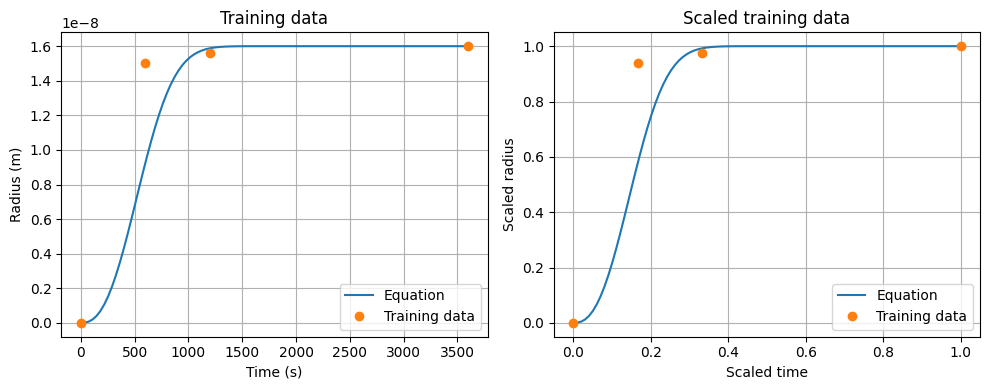

In [5]:

TIME_MAX = 3600  # seconds

# Time array
gt_times_X = np.linspace(0, TIME_MAX, 100)
eq = functools.partial(avrami_law, Ea=guessed_Ea, B=guessed_B, T=T, n=guessed_n, R=R, m=guessed_m)
gt_d_Y = eq(gt_times_X) # * 1e9


## REAL DATA
data220 = """T,time,d\n
220,0,0\n
220,10,15\n
220,20,15.6\n
220,60,16"""
data190 = """190,0,0\n
190,10,10.5\n
190,30,12.9\n
190,60,13.9"""

data = [[0,0], [10,15], [20,15.6], [60,16]]
data = torch.tensor(data, dtype=torch.float32)
train_times_X = data[:, 0].reshape(-1, 1) * 60
train_d_Y = data[:, 1].reshape(-1, 1) * 1e-9


# Scale data
scaler_X = TorchMinMaxScaler()
scaler_Y = TorchMinMaxScaler()

# Fit and transform the training data
eq_times_X_scaled = scaler_X.fit_transform(gt_times_X.reshape(-1, 1)).type(torch.float32)
eq_d_Y_scaled = scaler_Y.fit_transform(gt_d_Y.reshape(-1, 1)).type(torch.float32)

# Transform test data using the already fitted scalers
train_times_X_scaled = scaler_X.transform(train_times_X.reshape(-1, 1)).type(torch.float32)
train_d_Y_scaled = scaler_Y.transform(train_d_Y.reshape(-1, 1)).type(torch.float32)


# Plot
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(gt_times_X, gt_d_Y, label="Equation")
plt.plot(train_times_X, train_d_Y , 'o', label="Training data")
# noisy data
plt.grid()
plt.legend()
plt.title("Training data")
plt.xlabel("Time (s)")
plt.ylabel("Radius (m)")
plt.subplot(1, 2, 2)
plt.plot(eq_times_X_scaled, eq_d_Y_scaled, label="Equation")
plt.plot(train_times_X_scaled.cpu().numpy(), train_d_Y_scaled.cpu().numpy() , 'o', label="Training data")
plt.grid()
plt.legend()
plt.title("Scaled training data")
plt.xlabel("Scaled time")
plt.ylabel("Scaled radius")
plt.tight_layout()
plt.show(block=False)

Optimized Ea: 35000.00 J/mol (6.57e+19)
Optimized B: 5.84e-01 m/s (1.02e+16)
Optimized n: 0.43 (1.04e+09)
Optimized m: 1.32 (3.36e+15)


/tmp/ipykernel_3968355/4205355427.py:13: RuntimeWarning: overflow encountered in exp
  d = r_max*(1 - np.exp(-K * t**n))
/tmp/ipykernel_3968355/4205355427.py:13: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  d = r_max*(1 - np.exp(-K * t**n))


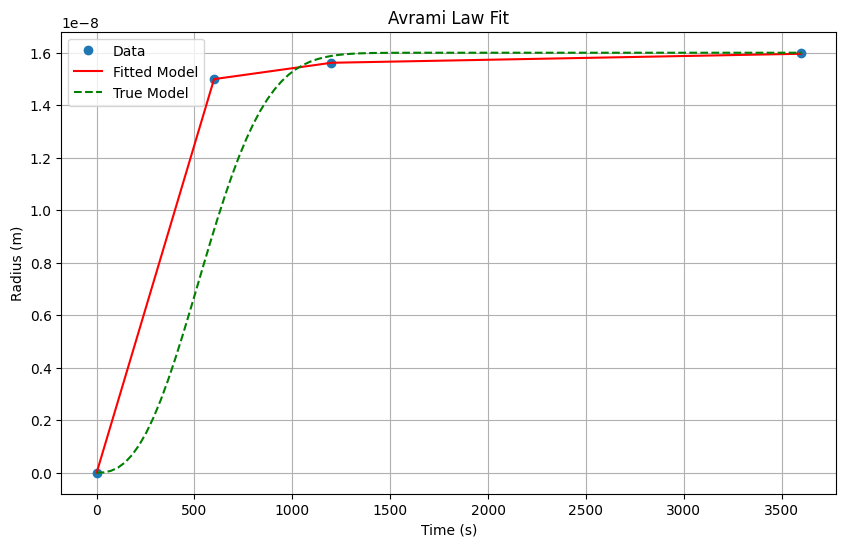

In [6]:
# Estimation parameters

import numpy as np
from scipy.optimize import least_squares

times = train_times_X.flatten().numpy()
X     = train_d_Y.flatten().numpy()


# perform a least squares fit
def residuals(params, t, d):
    Ea, B, n, m = params
    R = 8.314
    d_model = avrami_law(t=t, Ea=Ea, R=R, T=T, B=B, n=n, m=m)
    return d - d_model
# Initial guess for parameters
initial_guess = [guessed_Ea, guessed_B, guessed_n, guessed_m]
# Perform least squares optimization
res = least_squares(residuals, initial_guess, args=(times, X), method='lm')


# Extract optimized parameters
Ea_opt, B_opt, n_opt, m_opt = res.x
try:
    J = res.jac
    cov = np.linalg.inv(J.T.dot(J))
    var = np.sqrt(np.diagonal(cov))
except np.linalg.LinAlgError:
    print("Jacobian is singular, cannot compute covariance matrix.")
    var = [float("nan"), float("nan"), float("nan"), float("nan")]


print(f"Optimized Ea: {Ea_opt:.2f} J/mol ({var[0]:.2e})")
print(f"Optimized B: {B_opt:.2e} m/s ({var[1]:.2e})")
print(f"Optimized n: {n_opt:.2f} ({var[2]:.2e})")
print(f"Optimized m: {m_opt:.2f} ({var[3]:.2e})")


# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(train_times_X, X, 'o', label='Data')
plt.plot(train_times_X, avrami_law(train_times_X, Ea_opt, R, T, B_opt, n_opt, m_opt), label='Fitted Model', color='red')
plt.plot(gt_times_X, gt_d_Y, label='True Model', color='green', linestyle='--')
plt.xlabel('Time (s)')
plt.ylabel('Radius (m)')
plt.title('Avrami Law Fit')
plt.legend()
plt.grid()
plt.show(block=False)


In [7]:
import os


vannilla_pretrained = "vanilla_pretrained_concentration_mod.pth"
vanilla = DiscoveryNet(1, 3, loss2=None, loss2_weight=1, epochs=30000, lr=1e-4).to(DEVICE)
retrain = True
if os.path.exists(vannilla_pretrained):
    try:
        vanilla.load_state_dict(torch.load(vannilla_pretrained))
        print("Loaded pretrained model")
        retrain = False
    except Exception as e:
        print("Error loading pretrained model, retraining" , e)    

if retrain:
    losses = vanilla.fit(train_times_X_scaled.to(DEVICE), train_d_Y_scaled.to(DEVICE), scaler_Y)
    plt.plot(losses)
    plt.yscale('log')
    torch.save(vanilla.state_dict(), vannilla_pretrained)


Loaded pretrained model


Epoch 0/100000, loss: 0.323714 - data_loss: 0.223071 - physic_loss: 0.100643 - Ea=35003.50, B=1.00e-03, n=2.00, m=1.00e-02
Epoch 10000/100000, loss: 0.115263 - data_loss: 0.005020 - physic_loss: 0.110243 - Ea=29246.75, B=1.21e-03, n=1.68, m=1.23e-02
Epoch 20000/100000, loss: 0.102071 - data_loss: 0.002702 - physic_loss: 0.099370 - Ea=23303.58, B=1.54e-03, n=2.12, m=1.57e-02
Epoch 30000/100000, loss: 0.095548 - data_loss: 0.001867 - physic_loss: 0.093681 - Ea=24859.86, B=1.44e-03, n=2.18, m=1.48e-02
Epoch 40000/100000, loss: 0.092433 - data_loss: 0.001470 - physic_loss: 0.090963 - Ea=25618.34, B=1.40e-03, n=2.24, m=1.43e-02
Epoch 50000/100000, loss: 0.091217 - data_loss: 0.001229 - physic_loss: 0.089988 - Ea=26832.26, B=1.34e-03, n=2.27, m=1.37e-02
Epoch 60000/100000, loss: 0.090508 - data_loss: 0.001069 - physic_loss: 0.089439 - Ea=27218.13, B=1.32e-03, n=2.30, m=1.35e-02
Epoch 70000/100000, loss: 0.089508 - data_loss: 0.000944 - physic_loss: 0.088564 - Ea=27774.84, B=1.29e-03, n=2.33,

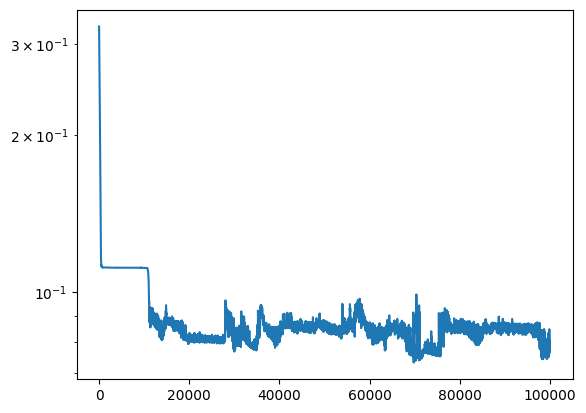

In [8]:
import torch.nn.functional as F


def set_seed(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def positive_activation(x, offset=1e-6):
    # First apply softplus, then a bias offset, then optionally exponentiate for sharper contrast
    return torch.exp(F.softplus(x)) + offset

def physics_loss(model: torch.nn.Module):
    global PHYSICAL_LOSS_SCALING_FACTOR

    # Create time input for PINN
    ts = torch.linspace(0, TIME_MAX, steps=100, dtype=torch.float32).view(-1, 1).to(DEVICE).requires_grad_(True)
    ts_scaled = scaler_X.transform(ts)

    # Predict radius
    out = model(ts_scaled)
    # d, Ea_net, A_net, n_net = out[:, 0], out[:, 1], out[:, 2], out[:, 3]  # [-1, 1] [0, 1]
    d = out
    d = scaler_Y.inverse_transform(d)
    
    #Ea = torch.nn.functional.softplus(Ea_net) * 1e5
    #A = torch.nn.functional.softplus(A_net) * 1e-3
    # Ea = Ea_net * 1e5 
    # A = A_net * 1e-3

    Ea = model.Ea
    B =  model.B
    n =  model.n
    m = model.m
    T_tensor = torch.tensor(T, dtype=torch.float32, device=DEVICE, requires_grad=True)

    # Compute model's derivative wrt time
    dd = torch.autograd.grad(
        d, ts, 
        grad_outputs=torch.ones_like(d), 
        create_graph=True
    )[0]

    # Compute K
    K = B * T_tensor.pow(m) * torch.exp(-Ea / (R * T_tensor))    
    # Compute the derivative of d(t) with respect to t
    derived_eq = K * n * ts.pow(n - 1) * torch.exp(-K * ts.pow(n))
    derived_eq = derived_eq * 16e-9

    pde_residual = dd - derived_eq
    # pde_residual = pde_residual * 1e12

    physical_loss = torch.mean(pde_residual**2)

    if PHYSICAL_LOSS_SCALING_FACTOR is None:
        # Get the maximum residual value as a float
        val = torch.max(physical_loss).item()
        # Compute the order-of-magnitude exponent. For a value like 5.23e-6,
        # math.log10(val) ≈ -5.28, and floor(-5.28) gives -6.
        exponent = -math.floor(math.log10(val))
        # Set the scaling factor as 10 raised to the computed exponent.
        # PHYSICAL_LOSS_SCALING_FACTOR = 10 ** exponent
        PHYSICAL_LOSS_SCALING_FACTOR = 1/abs(exponent)
        # PHYSICAL_LOSS_SCALING_FACTOR = 1e10

        # PROBLEM: when 1/exponent is too small, loss is too "flat" and less sensitive to gradient descent
        # alpha = 1/abs(exponent)  # computed as before
        # delta = 0.1  # adjust this value as needed
        # alpha_eff = min(alpha + delta, 1.0)
        # # regularized_loss = scaled_loss ** alpha_eff
        # PHYSICAL_LOSS_SCALING_FACTOR = alpha_eff
    
    physical_loss = torch.pow(physical_loss, PHYSICAL_LOSS_SCALING_FACTOR)
    # physical_loss = torch.nn.functional.softplus(physical_loss)

    return physical_loss

# PHYSICAL_LOSS_SCALING_FACTOR = 1e-12
PHYSICAL_LOSS_SCALING_FACTOR = None

set_seed(0)
scaler_X = scaler_X.to(DEVICE)
scaler_Y = scaler_Y.to(DEVICE)
curr_train_times_X = train_times_X_scaled.to(DEVICE)
curr_train_d_Y = train_d_Y_scaled.to(DEVICE)


# net = DiscoveryNet(1, 3, loss2=physics_loss, loss2_weight=1, epochs=150000, lr=1e-4).to(DEVICE)
# net = DiscoveryNet(1, 3, loss2=physics_loss, loss2_weight=1, epochs=10000, lr=1e-4).to(DEVICE)
# net = DiscoveryNet(1, 3, loss2=physics_loss, loss2_weight=1, epochs=100000, lr=1e-4).to(DEVICE)
net = DiscoveryNet(1, 3, loss2=physics_loss, loss2_weight=1, epochs=100000, lr=1e-4).to(DEVICE)
# net = DiscoveryNet(1, 3, loss2=physics_loss, loss2_weight=2, epochs=500000, lr=1e-5).to(DEVICE)

# net.B = B_opt + (B_opt * 0.2)
# net.Ea = Ea_opt + (Ea_opt * 0.2)
# net.n = n_opt + (n_opt * 0.2)

losses = net.fit(curr_train_times_X, curr_train_d_Y, scaler_Y)

plt.plot(losses)
plt.yscale('log')

In [13]:
print(net.Ea.item(), net.B.item(), net.n.item(), net.m.item())

# print(positive_activation(net.Ea).item(), positive_activation(net.A).item(), positive_activation(net.n).item())

28745.630859375 0.0012471743393689394 2.3963141441345215 0.012783139944076538


Predicted B: 1.2472e-03, Guess B: 5.8368e-01  -  difference: -5.8243e-01
Predicted Ea: 28745.63, Guess Ea: 35000.00  -  difference: -6254.37
Predicted n: 2.3963, Guess n: 0.4318  -  difference: 1.96
Predicted m: 1.2783e-02, Guess m: 1.2783e-02  -  difference: -1.31e+00


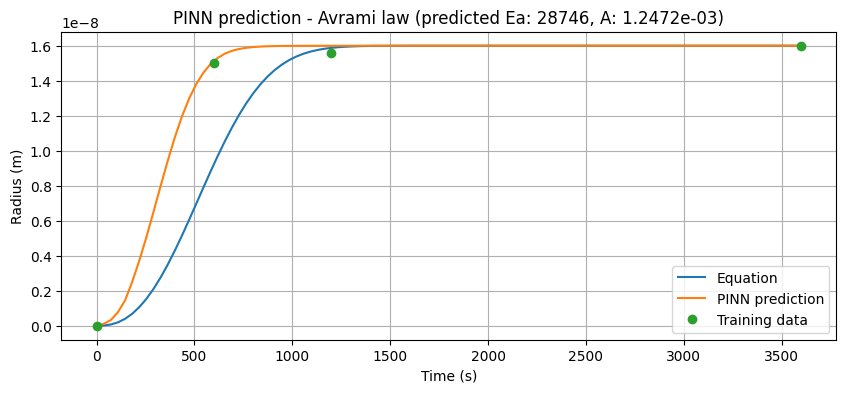

/tmp/ipykernel_3968355/4205355427.py:13: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  d = r_max*(1 - np.exp(-K * t**n))


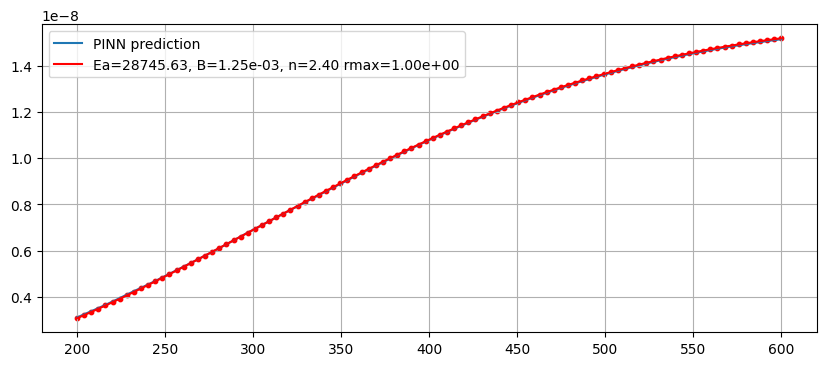

In [14]:
# plot the prediction on gt data

d = net.predict(eq_times_X_scaled)
d = torch.tensor(d, dtype=torch.float32, device=DEVICE)
d = scaler_Y.inverse_transform(d)
d = d.cpu().numpy()
Ea_net = net.Ea.item()
B_net = net.B.item()
n_net = net.n.item()
m_net = net.m.item()

# expected:
Ea = Ea_net
B = B_net
n = n_net
m = m_net

# Ea_opt, A_opt, n_opt
B_expected = B_opt
Ea_expected = Ea_opt
n_expected = n_opt
m_expected = m_opt
# r_max_expected = r_max_opt = r_max

print(f"Predicted B: {B:.4e}, Guess B: {B_expected:.4e}  -  difference: {(B - B_expected):.4e}")
print(f"Predicted Ea: {Ea:.2f}, Guess Ea: {Ea_expected:.2f}  -  difference: {(Ea - Ea_expected):.2f}")
print(f"Predicted n: {n_net:.4f}, Guess n: {n_expected:.4f}  -  difference: {(n - n_expected):.2f}")
print(f"Predicted m: {m_net:.4e}, Guess m: {m:.4e}  -  difference: {(m_net - m_expected):.2e}")
# print(f"Predicted r_max: {r_max:.2e}, Guess r_max: {r_max_expected:.2e}  -  abs difference: {abs(r_max - r_max_expected):.2e}")

vanilla_pred = vanilla.predict(eq_times_X_scaled)
vanilla_pred = torch.tensor(vanilla_pred, dtype=torch.float32, device=DEVICE)
vanilla_d = vanilla_pred[:, 0]
vanilla_d = scaler_Y.inverse_transform(vanilla_d)
vanilla_d = vanilla_d.cpu().numpy()
plt.figure(figsize=(10, 4))
# plt.subplot(1, 2, 1)
plt.plot(gt_times_X, gt_d_Y, label="Equation")
plt.plot(gt_times_X, d, label="PINN prediction")
# plt.plot(gt_times_X, vanilla_d, label="Vanilla net")
# plot train data
plt.plot(train_times_X, train_d_Y , 'o', label="Training data")
plt.title(f"PINN prediction - Avrami law (predicted Ea: {Ea:.0f}, A: {B:.4e})")
plt.xlabel("Time (s)")
plt.ylabel("Radius (m)")
plt.grid()
plt.legend()
plt.show()


# # plot all Ea and A values
# plt.figure(figsize=(10, 4))
# plt.subplot(1, 3, 1)
# plt.plot(gt_times_X, Ea, label="Ea")
# plt.legend()
# plt.grid()
# plt.subplot(1, 3, 2)
# plt.plot(gt_times_X, A, label="A")
# plt.legend()
# plt.grid()
# plt.subplot(1, 3, 3)
# plt.plot(gt_times_X, n, label="n")
# plt.legend()
# plt.grid()
# plt.show()


plt.figure(figsize=(10, 4))
# plot avrami eq using predicted A and Ea
times = torch.linspace(200, 600, 100)
# times = torch.linspace(350, 400, 100)
# times = torch.linspace(0, TIME_MAX, 100)

times_s = scaler_X.transform(times.reshape(-1, 1)).type(torch.float32).to(DEVICE)
times_s = times_s.reshape(-1, 1)
d = net.predict(times_s)
d = torch.tensor(d, dtype=torch.float32, device=DEVICE)
d = scaler_Y.inverse_transform(d)
d = d.cpu().numpy()
plt.plot(times.cpu().numpy(), d, label="PINN prediction")

eq_temp = functools.partial(avrami_law, B=B, Ea=Ea, T=T, n=n, m=m, R=R)
eq_d_Y = eq_temp(times)
plt.plot(times, eq_d_Y, label=f"Ea={Ea:.2f}, B={B:.2e}, n={n:.2f} rmax={r_max:.2e}", color='red')
plt.scatter(times.cpu().numpy(), eq_d_Y, color='red', s=10)
plt.legend()
plt.grid()
plt.show()

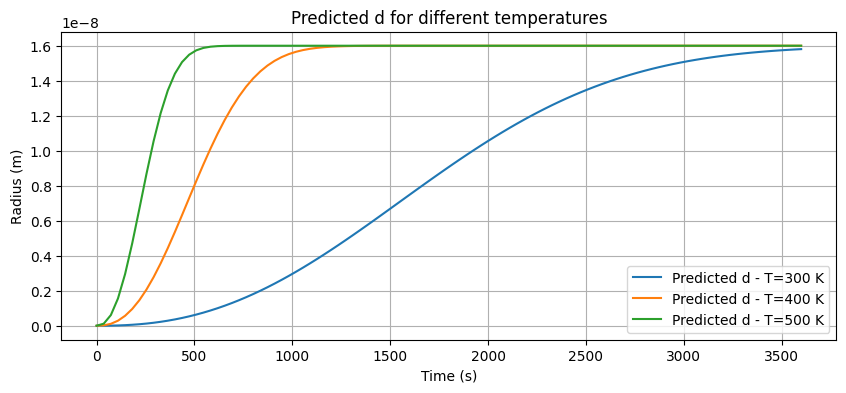

In [15]:

eq_temp = functools.partial(avrami_law, B=B, Ea=Ea, n=n, m=m, R=R)

times = np.linspace(0, TIME_MAX, 100)

plt.figure(figsize=(10, 4))
for temp in [300, 400, 500]:
    expeced_d = eq_temp(times, T=temp)
    plt.plot(times, expeced_d, label=f"Predicted d - T={temp} K")

plt.title("Predicted d for different temperatures")
plt.xlabel("Time (s)")
plt.ylabel("Radius (m)")
plt.legend()
plt.grid()
plt.show()

## ONE WAY
t = [0, 1, 2, ...] # seconds for a total of N steps
d, Ea, A = nn(t)

at the end you have
- d -> [N]
- Ea -> [N] mean() std()
- A -> [N] mean() std()
- Ea and A uncertainty (std) -> DEPENDENT ON THE TIME

## SECOND WAY
t = [0, 1, 2, ...] # seconds for a total of N steps
d = nn(t)
Ea = nn.Ea # learned 
A = nn.A # learned 

- d -> [N]
- NO UNCERTAINTY IN Ea
- INDEPENDENT FROM THE TIME

/tmp/ipykernel_3968355/4205355427.py:13: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  d = r_max*(1 - np.exp(-K * t**n))


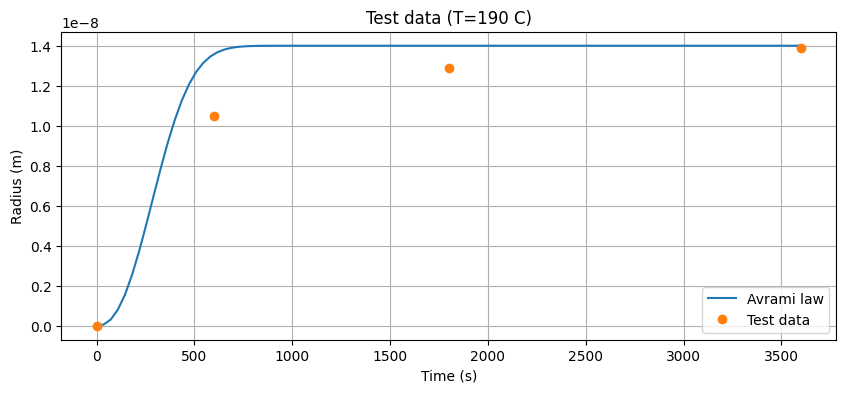

In [25]:
test_T = 190 + 273.15
test_data = [
    [0,0],
    [10*60,10.5* 1e-9],
    [30*60,12.9* 1e-9],
    [60*60,13.9* 1e-9]
]
test_times = torch.linspace(0, TIME_MAX, 100)
test_data = torch.tensor(test_data, dtype=torch.float32)
# test_r_max = 14e-9

predicted_Ea = Ea
predicted_B = B
predicted_n = n
predicted_m = m
predicted_r_max = 1.4e-8

plt.figure(figsize=(10, 4))
eq_test = functools.partial(avrami_law, B=predicted_B, Ea=predicted_Ea, m=predicted_m, n=predicted_n, R=R, r_max=predicted_r_max)
law = eq_test(test_times, T=test_T)
plt.plot(test_times, law, label="Avrami law")
plt.plot(test_data[:, 0], test_data[:, 1], 'o', label="Test data")
plt.title("Test data (T=190 C)")
plt.xlabel("Time (s)")
plt.ylabel("Radius (m)")
plt.legend()
plt.grid()
plt.show()

